In [23]:
from pathlib import Path
import rasterio
from rasterio.windows import Window
import matplotlib.pyplot as plt
import numpy as np

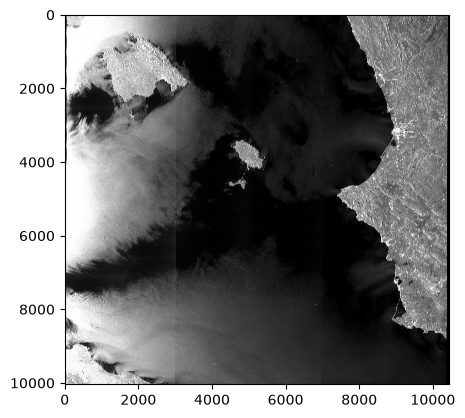

x_max = 10449
y_max = 10039


In [24]:
file = next(Path(INPUT_FOLDER).glob("*.tiff"))

with rasterio.open(file) as src:
    original = src.read(1, masked=True)

vmin, vmax = np.percentile(original.compressed(), [5, 95])

plt.imshow(original, cmap="gray",vmin=vmin, vmax=vmax)
plt.show()

y_max = original.shape[0] - 1
x_max = original.shape[1] - 1

print("x_max =", x_max)
print("y_max =", y_max)

In [25]:
def cut_tiffs0(folder=INPUT_FOLDER):
    pieces = []
    for file in sorted(Path(folder).iterdir()):
        if not file.is_file() or file.suffix.lower() not in (".tif", ".tiff"):
            continue
        with rasterio.open(file) as src:
            for y in range(0, src.height, 512):
                for x in range(0, src.width, 512):
                    piece = src.read(
                        window=Window(x, y, 512, 512),
                        boundless=True, fill_value=0,
                    )
                    pieces.append(piece[0] if src.count == 1 else piece)
        print(f"{file.name}: done", flush=True)
    return pieces


if __name__ == "__main__":
    pieces = cut_tiffs0()
    print(f"{len(pieces)} pieces")



1.tiff: done
420 pieces


In [26]:
def cut_tiffs1(folder=INPUT_FOLDER):
    pieces = []
    for file in sorted(Path(folder).iterdir()):
        if not file.is_file() or file.suffix.lower() not in (".tif", ".tiff"):
            continue
        with rasterio.open(file) as src:
            for y in range(0, src.height, 512):
                for x in range(256 , src.width, 512):
                        piece = src.read(
                            window=Window(x, y, 512, 512),
                            boundless=True, fill_value=0,
                        )
                        pieces.append(piece[0] if src.count == 1 else piece)
            print(f"{file.name}: done", flush=True)
        return pieces


if __name__ == "__main__":
    pieces = cut_tiffs1()
    print(f"{len(pieces)} pieces")

1.tiff: done
400 pieces


1.tiff: done


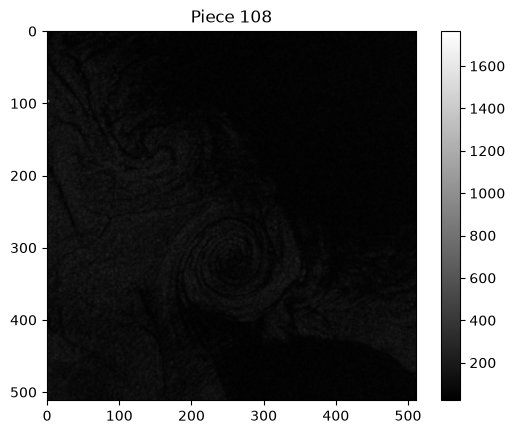

In [40]:
pieces = cut_tiffs1()
index = 108
piece = pieces[index]
if piece.ndim == 3:
    piece = piece[0]

plt.imshow(piece, cmap="grey")
plt.title(f"Piece {index}")
plt.colorbar()
plt.show()


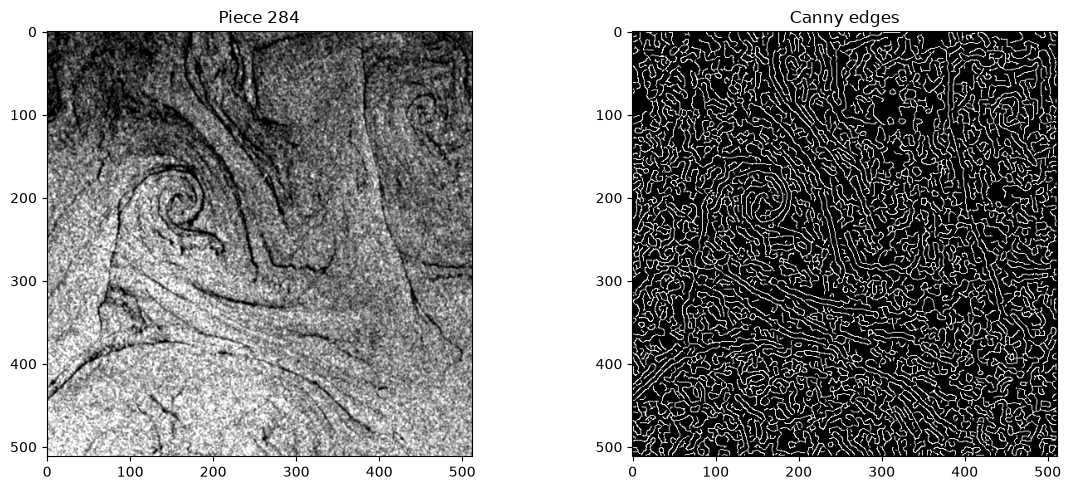

In [108]:
#canny
from skimage.feature import canny
from skimage.transform import hough_circle, hough_circle_peaks

#test on 108,284，282，266
index = 284
image = pieces[index].astype(float)

# 增强对比度，归一化到 0～1
lo, hi = np.percentile(image, [2, 98])
image = np.clip((image - lo) / max(hi - lo, 1e-12), 0, 1)

# 提取边缘
edges = canny(
    image,
    sigma=2.3, #2.3
    low_threshold=0.08,
    high_threshold=0.18,
)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].imshow(image, cmap="gray")
axes[0].set_title(f"Piece {index}")

axes[1].imshow(edges, cmap="gray")
axes[1].set_title("Canny edges")

plt.tight_layout()
plt.show()





x=151, y=199, radius=40, score=0.384


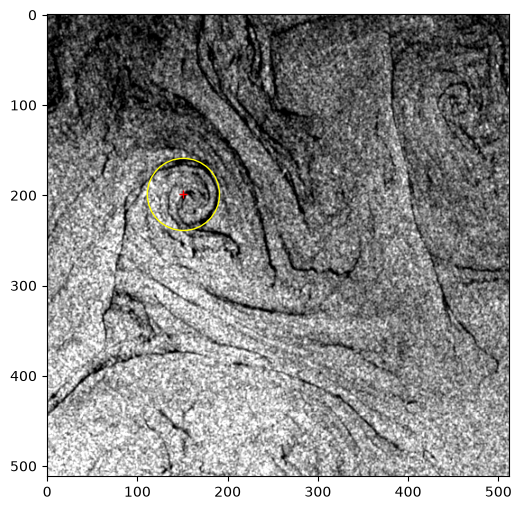

In [109]:
#hough

radii = np.arange(40, 150, 2)
votes = hough_circle(edges, radii)

scores, xs, ys, rs = hough_circle_peaks(
    votes, radii, total_num_peaks=1
)

fig, ax = plt.subplots(figsize=(6, 6))
ax.imshow(image, cmap="gray")

for score, x, y, r in zip(scores, xs, ys, rs):
    ax.add_patch(
        plt.Circle((x, y), r, fill=False, color="yellow")
    )
    ax.plot(x, y, "r+")
    print(f"x={x}, y={y}, radius={r}, score={score:.3f}")

plt.show()

Scanning 400 pieces...
Processing 1/400
Processing 21/400
Processing 41/400
Processing 61/400
Processing 81/400
Processing 101/400
Processing 121/400
Processing 141/400
Processing 161/400
Processing 181/400
Processing 201/400
Processing 221/400
Processing 241/400
Processing 261/400
Processing 281/400
Processing 301/400
Processing 321/400
Processing 341/400
Processing 361/400
Processing 381/400

Top candidates (indices start at 0):
index=108, rank=0.165, Hough=0.432, alignment=0.383, radius=46
index=68, rank=0.083, Hough=0.422, alignment=0.197, radius=44
index=382, rank=0.069, Hough=0.404, alignment=0.170, radius=42
index=81, rank=0.055, Hough=0.375, alignment=0.146, radius=44
index=249, rank=0.049, Hough=0.427, alignment=0.115, radius=40
index=282, rank=0.048, Hough=0.409, alignment=0.117, radius=40
index=19, rank=0.046, Hough=0.409, alignment=0.113, radius=40
index=44, rank=0.046, Hough=0.402, alignment=0.115, radius=44
index=216, rank=0.041, Hough=0.409, alignment=0.100, radius=40
in

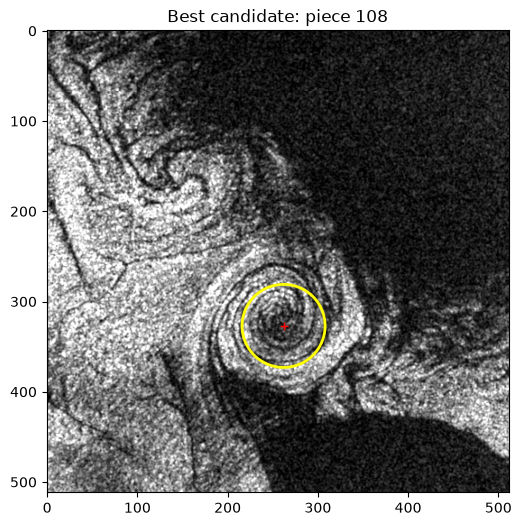


Best candidate index: 108


In [103]:
# Run after creating pieces: paste into a notebook cell, or %run -i this file.
# This ranks circular-texture candidates. The scores are not probabilities.
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter
from skimage.feature import canny
from skimage.transform import hough_circle

# Change these two settings.
sigma = 1.5
radii = np.arange(40, 121, 2)

ranking = []
print(f"Scanning {len(pieces)} pieces...", flush=True)

for index, piece in enumerate(pieces):
    if index % 20 == 0:
        print(f"Processing {index + 1}/{len(pieces)}", flush=True)

    image = piece.astype(float)
    if image.ndim == 3:
        image = image[0]
    lo, hi = np.percentile(image, [2, 98])
    image = np.clip((image - lo) / max(hi - lo, 1e-12), 0, 1)
    edges = canny(image, sigma=sigma, low_threshold=0.08, high_threshold=0.18)
    if not edges.any():
        continue

    votes = hough_circle(edges, radii)
    radius_index, y, x = np.unravel_index(votes.argmax(), votes.shape)
    hough_score = float(votes[radius_index, y, x])
    x, y, r = int(x), int(y), int(radii[radius_index])
    del votes

    # Circular bands have brightness gradients pointing toward/away from
    # their center. Check that direction across a surrounding annulus.
    gy, gx = np.gradient(gaussian_filter(image, sigma))
    yy, xx = np.indices(image.shape)
    distance = np.hypot(xx - x, yy - y)
    ring = edges & (distance >= 0.5 * r) & (distance <= 1.5 * r)
    angle = np.arctan2(gy, gx) - np.arctan2(yy - y, xx - x)
    alignment = float(np.cos(2 * angle)[ring].mean()) if ring.any() else 0.0
    rank_score = hough_score * max(0.0, alignment)

    ranking.append(dict(index=index, rank_score=rank_score,
                        hough_score=hough_score, alignment=alignment,
                        x=x, y=y, radius=r))

ranking.sort(key=lambda result: result["rank_score"], reverse=True)
print("\nTop candidates (indices start at 0):")
for result in ranking[:10]:
    print(f"index={result['index']}, rank={result['rank_score']:.3f}, "
          f"Hough={result['hough_score']:.3f}, alignment={result['alignment']:.3f}, "
          f"radius={result['radius']}")

best_index = None
if ranking and ranking[0]["rank_score"] > 0:
    best = ranking[0]
    best_index = index = best["index"]
    piece = pieces[best_index]
    if piece.ndim == 3:
        piece = piece[0]
    lo, hi = np.percentile(piece, [2, 98])
    fig, ax = plt.subplots(figsize=(6, 6))
    ax.imshow(piece, cmap="gray", vmin=lo, vmax=hi)
    ax.add_patch(plt.Circle((best["x"], best["y"]), best["radius"],
                           fill=False, color="yellow", linewidth=2))
    ax.plot(best["x"], best["y"], "r+")
    ax.set_title(f"Best candidate: piece {best_index}")
    plt.show()
    print(f"\nBest candidate index: {best_index}")
else:
    print("No candidate with positive circular-direction support.")
